# 07 — Logistics Analysis
## Superstore Logistics Analytics

### Objetivo

Analisar o tempo decorrido entre o registro dos pedidos e seu envio, identificando diferenças na duração do processamento e no comportamento das modalidades de envio.

A análise será realizada no nível de pedido e terá caráter descritivo. Como a base não possui prazo prometido, data efetiva de entrega ou SLA, os resultados não serão interpretados como atrasos ou cumprimento de prazo.

## 1. Configuração e Base Analítica

### 1.1 — Configuração do Ambiente e Carregamento dos Dados

A análise utiliza a camada de dados processados criada e validada nas etapas anteriores do projeto.

Nesta etapa, o objetivo é configurar o ambiente, localizar a fonte analítica e carregar os dados necessários para a construção da visão logística por pedido.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "sales_data_clean.parquet"
)

print(f"Raiz do projeto: {PROJECT_ROOT}")
print(f"Fonte analítica: {PROCESSED_DATA_PATH}")
print(f"Arquivo disponível: {PROCESSED_DATA_PATH.exists()}")

Raiz do projeto: c:\superstore-analytics
Fonte analítica: c:\superstore-analytics\data\processed\sales_data_clean.parquet
Arquivo disponível: True


In [2]:
df = pd.read_parquet(PROCESSED_DATA_PATH)

print(f"Registros carregados: {len(df):,}")
print(f"Colunas disponíveis: {df.shape[1]}")

Registros carregados: 9,799
Colunas disponíveis: 19


### 1.2 — Construção da Visão Logística por Pedido

A base processada possui granularidade de item de pedido. Para a análise logística, será construída uma visão consolidada no nível de Order ID.

Antes da agregação, será validado se Order Date, Ship Date, Ship Mode e Shipping Days permanecem consistentes entre as diferentes linhas pertencentes ao mesmo pedido.

Essa validação evita consolidar pedidos que apresentem informações logísticas conflitantes.

In [3]:
logistics_consistency = (
    df.groupby("Order ID")
    .agg({
        "Order Date": "nunique",
        "Ship Date": "nunique",
        "Ship Mode": "nunique",
        "Shipping Days": "nunique"
    })
)

logistics_conflicts = (
    logistics_consistency > 1
).sum()

logistics_conflicts

Order Date       0
Ship Date        0
Ship Mode        0
Shipping Days    0
dtype: int64

In [4]:
logistics_orders = (
    df[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Ship Mode",
            "Shipping Days"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print(f"Pedidos na visão logística: {len(logistics_orders):,}")
print(
    "Order IDs distintos:",
    f"{logistics_orders['Order ID'].nunique():,}"
)

logistics_orders.head()

Pedidos na visão logística: 4,922
Order IDs distintos: 4,922


,Order ID,Order Date,Ship Date,Ship Mode,Shipping Days
0,CA-2017-106075,2017-09-18,2017-09-23,Standard Class,5
1,CA-2018-101798,2018-12-11,2018-12-15,Standard Class,4
2,CA-2016-147851,2016-12-03,2016-12-08,Standard Class,5
3,CA-2018-164826,2018-12-28,2019-01-04,Standard Class,7
4,CA-2017-164511,2017-11-19,2017-11-24,Standard Class,5


## 2. Tempo de Processamento dos Pedidos

### 2.1 — Distribuição do Tempo de Envio

O tempo de processamento representa o número de dias decorridos entre o registro do pedido e sua data de envio.

Nesta etapa, será analisada a distribuição de Shipping Days no nível de pedido, permitindo identificar o comportamento típico e a amplitude dos tempos observados, sem interpretá-los como atrasos ou cumprimento de SLA.

In [5]:
shipping_metrics = (
    logistics_orders["Shipping Days"]
    .describe()
    .loc[["min", "25%", "50%", "75%", "max"]]
    .to_frame(name="Shipping Days")
)

shipping_metrics["Shipping Days"] = (
    shipping_metrics["Shipping Days"]
    .map(lambda value: f"{value:.0f} dias")
)

shipping_metrics

,Shipping Days
min,0 dias
25%,3 dias
50%,4 dias
75%,5 dias
max,7 dias


#### Interpretação

O tempo entre o registro do pedido e o envio apresenta distribuição relativamente concentrada.

A mediana é de 4 dias, enquanto metade dos pedidos apresenta tempos entre 3 e 5 dias. O menor tempo observado é de 0 dias, indicando pedidos enviados no mesmo dia do registro, e o máximo alcança 7 dias.

Os resultados mostram que a maior parte dos pedidos está concentrada em uma faixa relativamente estreita de tempo de processamento. Esses valores, entretanto, descrevem apenas o intervalo entre pedido e envio e não representam atraso ou cumprimento de prazo.

### 2.2 — Pedidos com Maior Tempo de Processamento

Após caracterizar a distribuição geral, a análise passa a observar a faixa superior dos tempos de processamento.

O objetivo é quantificar a participação dos pedidos que levaram 6 ou 7 dias entre o registro e o envio, sem classificá-los como atrasos, uma vez que a base não contém prazo prometido ou SLA.

In [6]:
upper_shipping_range = (
    logistics_orders[
        logistics_orders["Shipping Days"] > 5
    ]
    .groupby("Shipping Days")
    .size()
    .reset_index(name="Orders")
)

upper_shipping_range["Order_Share"] = (
    upper_shipping_range["Orders"]
    / len(logistics_orders)
)

upper_shipping_range["Shipping Days"] = (
    upper_shipping_range["Shipping Days"]
    .map(lambda value: f"{value} dias")
)

upper_shipping_range["Order_Share"] = (
    upper_shipping_range["Order_Share"]
    .map(lambda value: f"{value:.2%}")
)

upper_shipping_range

,Shipping Days,Orders,Order_Share
0,6 dias,584,11.87%
1,7 dias,303,6.16%


#### Interpretação

Os pedidos com tempos de processamento acima do terceiro quartil representam uma parcela relevante da base.

Foram identificados 584 pedidos processados em 6 dias, equivalentes a 11,87% do total, e 303 pedidos processados em 7 dias, correspondentes a 6,16%.

Em conjunto, 887 pedidos (18,03%) apresentam tempos de processamento entre 6 e 7 dias.

Esses registros representam a faixa superior da distribuição observada, mas não podem ser classificados como atrasos, pois a base não contém prazo prometido ou SLA para comparação.

## 3. Desempenho por Modalidade de Envio

### 3.1 — Tempo de Envio por Ship Mode

As modalidades de envio podem apresentar diferentes padrões de tempo entre o registro do pedido e sua expedição.

Nesta etapa, serão comparados os tempos de processamento observados em cada Ship Mode, utilizando medidas de tendência central e dispersão para identificar diferenças entre as modalidades.

In [7]:
shipping_by_mode = (
    logistics_orders
    .groupby("Ship Mode")
    .agg(
        Orders=("Order ID", "nunique"),
        Average_Days=("Shipping Days", "mean"),
        Median_Days=("Shipping Days", "median"),
        Min_Days=("Shipping Days", "min"),
        Max_Days=("Shipping Days", "max")
    )
    .sort_values("Median_Days")
)

shipping_by_mode_display = shipping_by_mode.copy()

shipping_by_mode_display["Average_Days"] = (
    shipping_by_mode_display["Average_Days"]
    .map(lambda value: f"{value:.2f}")
)

shipping_by_mode_display["Median_Days"] = (
    shipping_by_mode_display["Median_Days"]
    .map(lambda value: f"{value:.0f}")
)

shipping_by_mode_display

,Orders,Average_Days,Median_Days,Min_Days,Max_Days
Ship Mode,,,,,
Same Day,261,0.05,0,0,1
First Class,772,2.19,2,1,4
Second Class,944,3.24,3,1,5
Standard Class,2945,5.00,5,3,7


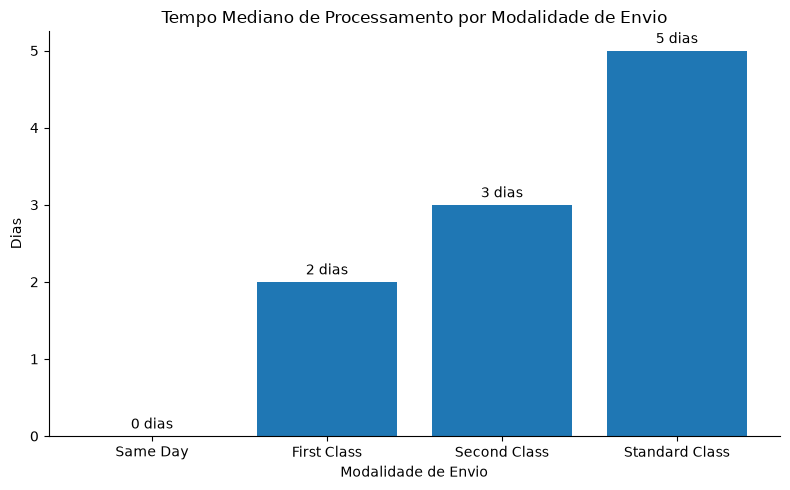

In [8]:
mode_order = [
    "Same Day",
    "First Class",
    "Second Class",
    "Standard Class"
]

median_by_mode = (
    shipping_by_mode
    .loc[mode_order, "Median_Days"]
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    median_by_mode.index,
    median_by_mode.values
)

ax.set_title("Tempo Mediano de Processamento por Modalidade de Envio")
ax.set_xlabel("Modalidade de Envio")
ax.set_ylabel("Dias")

ax.bar_label(
    bars,
    labels=[f"{value:.0f} dias" for value in median_by_mode.values],
    padding=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### Interpretação

As modalidades de envio apresentam diferenças claras no tempo observado entre o registro do pedido e sua expedição.

Same Day apresenta mediana de 0 dias, seguido por First Class com 2 dias, Second Class com 3 dias e Standard Class com 5 dias.

As médias permanecem próximas das respectivas medianas, reforçando a diferenciação observada entre as modalidades. Standard Class também apresenta a maior amplitude, variando entre 3 e 7 dias.

Os resultados descrevem o comportamento operacional observado de cada modalidade e não representam uma avaliação de cumprimento de prazo, pois a base não contém SLA ou prazo prometido.

### 3.2 — Participação das Modalidades nos Pedidos

Além das diferenças no tempo de processamento, é importante observar como os pedidos estão distribuídos entre as modalidades de envio.

Essa análise permite contextualizar os resultados anteriores, identificando quais modalidades possuem maior presença na operação observada.

In [9]:
ship_mode_share = (
    logistics_orders["Ship Mode"]
    .value_counts()
    .rename_axis("Ship Mode")
    .reset_index(name="Orders")
)

ship_mode_share["Order Share"] = (
    ship_mode_share["Orders"]
    / len(logistics_orders)
)

ship_mode_share["Order Share"] = (
    ship_mode_share["Order Share"]
    .map(lambda value: f"{value:.2%}")
)

ship_mode_share

,Ship Mode,Orders,Order Share
0,Standard Class,2945,59.83%
1,Second Class,944,19.18%
2,First Class,772,15.68%
3,Same Day,261,5.30%


#### Interpretação

A distribuição dos pedidos mostra forte predominância de Standard Class, responsável por 59,83% dos pedidos analisados.

Second Class representa 19,18%, seguido por First Class com 15,68%, enquanto Same Day possui participação de apenas 5,30%.

Esse resultado é relevante quando combinado com a análise anterior: Standard Class, além de concentrar a maior parte dos pedidos, apresenta o maior tempo mediano entre o registro e o envio, com 5 dias.

Assim, o comportamento logístico agregado da base é fortemente influenciado por essa modalidade.

## 4. Síntese da Análise Logística

### 4.1 — Principais Achados

A análise logística foi realizada no nível de pedido, considerando 4.922 pedidos e o tempo decorrido entre Order Date e Ship Date.

Os principais resultados foram:

- O tempo mediano entre o registro do pedido e o envio é de 4 dias, com metade dos pedidos concentrada entre 3 e 5 dias.
- A faixa superior da distribuição, correspondente a tempos de 6 ou 7 dias, reúne 887 pedidos, equivalentes a 18,03% do total.
- As modalidades apresentam padrões claramente distintos de processamento: Same Day possui mediana de 0 dias, First Class de 2 dias, Second Class de 3 dias e Standard Class de 5 dias.
- Standard Class concentra 59,83% dos pedidos, sendo simultaneamente a modalidade mais utilizada e aquela com maior tempo mediano de processamento.
- Como consequência de sua elevada participação, Standard Class exerce forte influência sobre o comportamento logístico agregado observado na base.

A análise evidencia diferenças consistentes entre as modalidades de envio. Entretanto, os resultados devem ser interpretados como características do processo observado e não como indicadores de atraso ou cumprimento de prazo, pois a base não contém SLA, prazo prometido ou data efetiva de entrega.